## 5-2. 합성곱 신경망 맛보기

**fashion_mnist 데이터셋**
- 운동화, 셔츠, 샌들 같은 작은 이미지의 모음으로, 열 가지로 분류될 수 있는 28*28 픽셀의 이미지 7만 개로 구성
- 0 : T-Shirt
- 1 : Trouser
- 2 : Pullover
- 3 : Dress
- 4 : Coat
- 5 : Sandal
- 6 : Shirt
- 7 : Sneaker
- 8 : Bag
- 9 : Ankle Boot

In [ ]:
# 라이브러리 호출
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.autograd import Variable
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms
from torch.utils.data import Dataset,DataLoader

In [ ]:
# GPU 혹은 CPU 장치 확인
device=torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [ ]:
# fashion_mnist 데이터셋 내려받기
train_dataset=torchvision.datasets.FashionMNIST(root='./data',
                                                transform=transforms.Compose([transforms.ToTensor()]),download=True)
test_dataset=torchvision.datasets.FashionMNIST(root='./data',train=False,
                                                transform=transforms.Compose([transforms.ToTensor()]),download=True)

100%|██████████| 26.4M/26.4M [00:01<00:00, 18.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 298kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.54MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.6MB/s]


In [ ]:
# fashion_mnist 데이터를 데이터로더에 전달
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=100)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=100)

- batch_size: 데이터를 배치로 묶어 줌. 여기에서는 batch_size=100으로 지정했기 때문 에 100개 단위로 데이터를 묶어서 불러옴

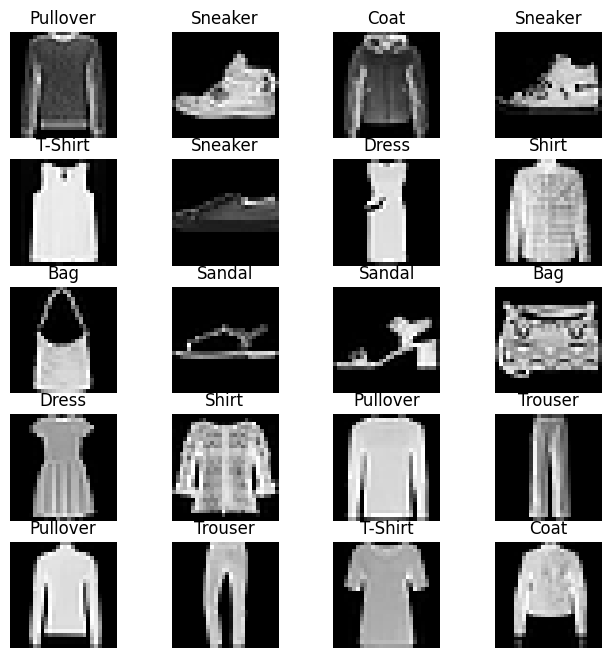

In [ ]:
# 분류에 사용될 클래스 정의
label_map={0: 'T-Shirt',1:'Trouser',2:'Pullover',3:'Dress',4:'Coat',5:'Sandal',6:'Shirt',7:'Sneaker',8:'Bag',9:'Ankle Boot'}

fig=plt.figure(figsize=(8,8));
columns=4;
rows=5;
for i in range(1,columns*rows+1):
  img_xy=np.random.randint(len(train_dataset))
  img=train_dataset[img_xy][0][0,:,:]
  fig.add_subplot(rows,columns,i)
  plt.title(label_map[train_dataset[img_xy][1]])
  plt.axis('off')
  plt.imshow(img,cmap='gray')
plt.show()

- train_dataset[img_xy] -> img_xy번째 데이터 샘플 선택 → 보통 (image, label) 형태

- train_dataset[img_xy][0] -> 샘플의 첫 번째 요소인 image tensor 선택

- [0,:,:] -> 이미지 tensor의 첫 번째 채널 선택 → : 는 해당 차원의 전체 범위를 의미

- 즉, [0,:,:] = [첫 번째 채널, 모든 행, 모든 열]

- 예를 들어 이미지 shape이 (1,28,28)이면:
1 : 채널 수, 28 : 높이, 28 : 너비 -> 따라서 결과 shape은 (28,28)가 되어 실제 이미지 픽셀 값만 추출하게 됨

In [ ]:
# 심층 신경망 모델 생성
class FashionDNN(nn.Module):
  def __init__(self):
    super(FashionDNN,self).__init__()
    self.fc1=nn.Linear(in_features=784,out_features=256)
    self.drop=nn.Dropout(0.25)
    self.fc2=nn.Linear(in_features=256,out_features=128)
    self.fc3=nn.Linear(in_features=128,out_features=10)
  def forward(self,input_data):
    out=input_data.view(-1,784)
    out=F.relu(self.fc1(out))
    out=self.drop(out)
    out=F.relu(self.fc2(out))
    out=self.fc3(out)
    return out

- 클래스(class) 형태의 모넬은 항상 torch.nn.Module을 상속받음. __init__()은 객체가 갖 는 속성 값을 초기화하는 역할을 하며 객체가 생성될 때 자동으로 호출됨. super( FashionDNN, self).__init__()은 nn.Module 클래스를 상속받겠다는 의미
- nn은 답러닝 모벨(네트워크) 구성에 펼요한 모률이 모여 있는 패키지이며, Linear는 단순 선형 회귀 모델을 만들때 사용. 이때 사용되는 파라미터는 다음과 같음
- in_features: 입력의 크기(input size)
- out_features: 출력의 크기(output size)
- torch.nn.Dropout(p)는 p만큼의 비율로 댄서의 값이 0이 되고, 0이 되지 않는 값들은 기존 값 에 (l/(l-p))만를 곱해져 커짐. 예를 들어 p=0.3이라는 의미는 전체 값 중 0.3의 확률로 0이 된다는 것이며, 0이 되지 않는 0.7에 해당하는 값은 (1/(1-0.7))만큼 커짐
- forward() 함수는 모댈이 학습 데이터를 입력받아서 순전파(forward propagation) 학습을 진행 시키며, 반드시 forward라는 이름의 함수여야 함. 즉 forward( )는 모댈이 학습 데이터를 입력받아서 순전파 연산을 진행하는 함수이며, 객체를 데이터와 함께 호출하면 자동으로 실행됨. 이때 순전파 연산이란 H(x) 식에 입력 x로부터 예측된 y를 얻는 것
- 파이토치에서 사용하는 뷰(view)는 넘파이의 reshape과 같은 역할로 댄서의 크기(shape)를 변경해 주는 역할. 따라서 input_data.view(-1 , 784)는 input_data를 (7, 784)의 크기로 변경하라는 의미
- 활성화함수를 지정할ㄷ 때는 다음 두 가지 방법이 가능함
- F.relu(): forward() 함수에서 정의
- nn.ReLU(): __init__() 함수에서 정의









In [ ]:
# 심층 신경망에서 필요한 파라미터 정의
learning_rate=0.001;
model=FashionDNN();
model.to(device)

criterion=nn.CrossEntropyLoss();
optimizer=torch.optim.Adam(model.parameters(),lr=learning_rate);
print(model)

FashionDNN(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:
# 심층 신경망을 이용한 모델 학습
num_epochs=5
count=0
loss_list=[]
iteration_list=[]
accuracy_list=[]
predictions_list=[]
labels_list=[]

for epoch in range(num_epochs):
  for images,labels in train_loader:
    images,labels=images.to(device),labels.to(device)
    train=Variable(images.view(100,1,28,28))
    labels=Variable(labels)
    outputs=model(train)
    loss=criterion(outputs,labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    count+=1

    if not (count%50):
      total=0
      correct=0
      for images,labels in test_loader:
        images,labels=images.to(device),labels.to(device)
        labels_list.append(labels)
        test=Variable(images.view(100,1,28,28))
        outputs=model(test)
        predictions=torch.max(outputs,1)[1].to(device)
        predictions_list.append(predictions)
        correct+=(predictions==labels).sum()
        total+=len(labels)

      accuracy=correct*100/total
      loss_list.append(loss.data)
      iteration_list.append(count)
      accuracy_list.append(accuracy)
    if not (count%500):
      print('Iteration: {},Loss: {}, Accuracy: {}%'.format(count,loss.data,accuracy))

Iteration: 500,Loss: 0.5777137875556946, Accuracy: 83.55999755859375%
Iteration: 1000,Loss: 0.4332965910434723, Accuracy: 84.31999969482422%
Iteration: 1500,Loss: 0.4017642140388489, Accuracy: 83.48999786376953%
Iteration: 2000,Loss: 0.3576337397098541, Accuracy: 85.52999877929688%
Iteration: 2500,Loss: 0.2640112638473511, Accuracy: 85.88999938964844%
Iteration: 3000,Loss: 0.303715318441391, Accuracy: 86.79000091552734%


- 최종적으로 정확도 86.79%로 높은 수치를 보여줌. 심층 신경망에 대한 모델 생성과 성능 평가가 완료됨

In [ ]:
# 합성곱 네트워크 생성
class FashionCNN(nn.Module):
  def __init__(self):
    super(FashionCNN,self).__init__()
    self.layer1=nn.Sequential(
      nn.Conv2d(in_channels=1,out_channels=32,kernel_size=3,padding=1),
      nn.BatchNorm2d(32),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2,stride=2)
      )
    self.layer2=nn.Sequential(
      nn.Conv2d(in_channels=32,out_channels=64,kernel_size=3),
      nn.BatchNorm2d(64),
      nn.ReLU(),
      nn.MaxPool2d(2)
      )
    self.fc1=nn.Linear(in_features=64*6*6,out_features=600)
    self.drop=nn.Dropout2d(0.25)
    self.fc2=nn.Linear(in_features=600,out_features=120)
    self.fc3=nn.Linear(in_features=120,out_features=10)

  def forward(self,x):
    out=self.layer1(x)
    out=self.layer2(out)
    out=out.view(out.size(0),-1) # 합성곱층에서 완전연결층으로 변경되기 때문에 데이터의 형태를 1차원으로 바꾸어 줍니다.
    out=self.fc1(out)
    out=self.drop(out)
    out=self.fc2(out)
    out=self.fc3(out)
    return out

- nn.Sequential은 여러 개의 계층을 하나의 컨테이너에 구현하는 방법
- nn.Conv2d( in_channels=1 , 0ut channels=32 , kernel size=3, padding=1)에서
- n_channels: 입력 채널의 수. 흑백 이미지는 1, RGB 값을 가진 이미지는 3을 가진 경우가 많음
- out_channels: 출력 채널의 수
- kernel_size: 커널 크기
- padding: 패딩 크기를 의미하는 것으로 출력 크기를 조정하기 위해 입력 데이터 주위에 0을 채움. 패딩 값이 클수록 출력 크기도 커짐

In [ ]:
# 합성곱 네트워크를 위한 파라미터 정의
learning_rate=0.001;
model=FashionCNN();
model.to(device)

criterion=nn.CrossEntropyLoss();
optimizer=torch.optim.Adam(model.parameters(),lr=learning_rate);
print(model)

FashionCNN(
  (layer1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=2304, out_features=600, bias=True)
  (drop): Dropout2d(p=0.25, inplace=False)
  (fc2): Linear(in_features=600, out_features=120, bias=True)
  (fc3): Linear(in_features=120, out_features=10, bias=True)
)


In [ ]:
# 모델 학습 및 성능 평가
num_epochs=5
count=0
loss_list=[]
iteration_list=[]
accuracy_list=[]
predictions_list=[]
labels_list=[]

for epoch in range(num_epochs):
  for images,labels in train_loader:
    images,labels=images.to(device),labels.to(device)
    train=Variable(images.view(100,1,28,28))
    labels=Variable(labels)
    outputs=model(train)
    loss=criterion(outputs,labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    count+=1

    if not (count%50):
      total=0
      correct=0
      for images,labels in test_loader:
        images,labels=images.to(device),labels.to(device)
        labels_list.append(labels)
        test=Variable(images.view(100,1,28,28))
        outputs=model(test)
        predictions=torch.max(outputs,1)[1].to(device)
        predictions_list.append(predictions)
        correct+=(predictions==labels).sum()
        total+=len(labels)

      accuracy=correct*100/total
      loss_list.append(loss.data)
      iteration_list.append(count)
      accuracy_list.append(accuracy)
    if not (count%500):
      print('Iteration: {},Loss: {}, Accuracy: {}%'.format(count,loss.data,accuracy))

Iteration: 500,Loss: 0.3038698434829712, Accuracy: 90.12999725341797%
Iteration: 1000,Loss: 0.25851595401763916, Accuracy: 90.63999938964844%
Iteration: 1500,Loss: 0.21887044608592987, Accuracy: 87.87999725341797%
Iteration: 2000,Loss: 0.21927781403064728, Accuracy: 90.2300033569336%
Iteration: 2500,Loss: 0.11775901913642883, Accuracy: 89.62999725341797%
Iteration: 3000,Loss: 0.16009598970413208, Accuracy: 90.62999725341797%


- 심층 신경망과 비교하여 정확도가 약간 더 높으나, 별 차이가 없기 때문에 더 간편한 심층 신경망만을 사용해도 무난할 것 같지만, 실제로 이미지 데이터가 많아지면 단순 심층 신경망으로는 정확한 특성 추출 및 분류가 불가능하므로 합성곱 신경망을 생성할 줄 알아야함